# 01 · Dataset Familiarization

What is in this dataset, how big is it, and what state is it in? Covers rubric criterion 1 (Problem Understanding & Dataset Familiarization).

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


## 1. The raw dataset at a glance

In [2]:
dq = json.loads((REPORTS / 'data_quality_report.json').read_text())
raw = dq['raw']
print('Source      :', dq['dataset']['name'])
print('URL         :', dq['dataset']['source_url'])
print('Licence     :', dq['dataset']['licence'])
print()
print(f"Rows        : {raw['n_rows']:,}")
print(f"Columns     : {raw['n_cols']}")
print(f"Invoices    : {raw['n_invoices']:,}")
print(f"Stock codes : {raw['n_stock_codes']:,}")
print(f"Customers   : {raw['n_customers']:,}")
print(f"Countries   : {raw['n_countries']}")
print(f"Date range  : {raw['date_min']}  ->  {raw['date_max']}")

Source      : UCI Online Retail II
URL         : https://archive.ics.uci.edu/dataset/502/online+retail+ii
Licence     : CC BY 4.0

Rows        : 1,067,371
Columns     : 9
Invoices    : 53,628
Stock codes : 5,305
Customers   : 5,942
Countries   : 43
Date range  : 2009-12-01 07:45:00  ->  2011-12-09 12:50:00


## 2. Columns, data types and missing values

In [3]:
miss = pd.DataFrame(raw['missing_by_column']).T
miss[['dtype', 'n_missing', 'pct_missing', 'n_unique']]

,dtype,n_missing,pct_missing,n_unique
invoice,str,0,0.0,53628
stock_code,str,0,0.0,5305
description,str,4382,0.4105,5698
quantity,float64,0,0.0,1057
invoice_date,datetime64[ns],0,0.0,47635
price,float64,0,0.0,2807
customer_id,float64,243007,22.7669,5942
country,str,0,0.0,43
source_sheet,str,0,0.0,2


`customer_id` is missing on a substantial share of rows. Those are genuine transactions without a registered customer, so they are kept: the forecasting target is units sold, which does not need a customer id.

## 3. Numeric summary of the raw columns

In [4]:
pd.DataFrame(raw['numeric_summary']).T

,count,mean,std,variance,min,q25,median,q75,q90,q95,q99,max,skew,n_negative,n_zero
quantity,1067371.0,9.938898,172.705794,29827.291308,-80995.00,1.00,3.0,10.00,24.00,30.00,100.0,80995.0,3.996145,22950.0,0.0
price,1067371.0,4.649388,123.553059,15265.358319,-53594.36,1.25,2.1,4.15,7.95,9.95,18.0,38970.0,-69.164734,5.0,6202.0


`quantity` is extremely right-skewed and contains negatives — the negatives are credit notes, handled explicitly in cleaning.

## 4. The cleaning pipeline, step by step

In [5]:
steps = pd.DataFrame(dq['cleaning']['steps'])
print(f"rows in : {dq['cleaning']['rows_in']:,}")
print(f"rows out: {dq['cleaning']['rows_out']:,} "
      f"({100 - dq['cleaning']['pct_removed_total']:.2f}% retained)")
steps[['step', 'rows_before', 'rows_after', 'rows_removed', 'pct_removed']]

rows in : 1,067,371
rows out: 1,024,819 (96.01% retained)


,step,rows_before,rows_after,rows_removed,pct_removed
0,drop_exact_duplicates,1067371,1055238,12133,1.1367
1,drop_missing_key_fields,1055238,1055238,0,0.0000
2,split_cancellations,1055238,1035805,19433,1.8416
3,drop_non_product_codes,1035805,1030931,4874,0.4706
4,drop_nonpositive_quantity,1030931,1027505,3426,0.3323
5,drop_nonpositive_price,1027505,1024826,2679,0.2607
6,drop_extreme_line_quantity,1024826,1024819,7,0.0007


In [6]:
for s in dq['cleaning']['steps']:
    print(f"{s['step']}\n    {s['reason'][:300]}\n")

drop_exact_duplicates
    Identical rows on every column are re-scans of the same line, not two separate sales.

drop_missing_key_fields
    A line with no date or no stock code cannot enter a time series.

split_cancellations
    Invoices prefixed 'C' are credit notes. They are removed from the demand series but retained separately as a returns signal.

drop_non_product_codes
    Service lines (POST, DOT, M, BANK CHARGES, ADJUST, TEST*) are not stockable items and must not be forecast or reordered. Most frequent removed codes: {'POST': 1893, 'DOT': 1443, 'M': 878, 'C2': 275, 'ADJUST': 36, 'BANK CHARGES': 35, 'DCGS0058': 31, 'GIFT_0001_20': 29, 'GIFT_0001_30': 29, 'DCGSSGIRL'

drop_nonpositive_quantity
    Zero or negative quantities on a non-cancellation invoice are adjustments, not demand.

drop_nonpositive_price
    Zero-price lines are samples, write-offs or data-entry errors; they would distort the revenue-based SKU ranking.

drop_extreme_line_quantity
    Single lines above 10000

## 5. Trading-day structure — a real finding

,invoices
Mon,6245
Tue,7146
Wed,7115
Thu,8167
Fri,5987
Sat,30
Sun,4824


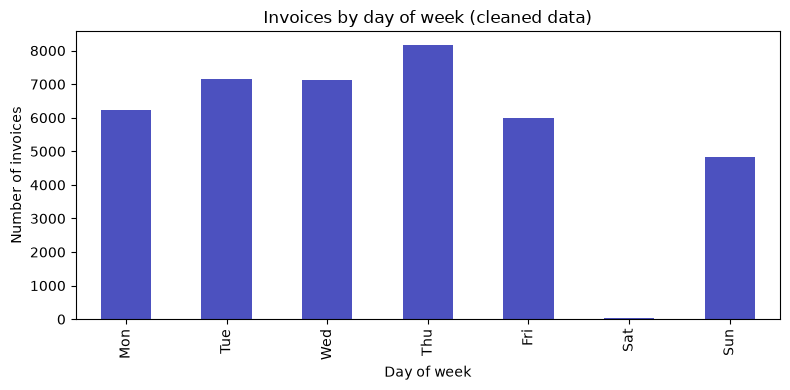


Saturday invoices: 30 vs weekday average: 6932


In [7]:
wk = dq['clean']['invoices_by_weekday']
s = pd.Series(wk)
display(s.to_frame('invoices'))
ax = s.plot.bar(figsize=(8, 4), color='#4c51bf')
ax.set_title('Invoices by day of week (cleaned data)')
ax.set_ylabel('Number of invoices'); ax.set_xlabel('Day of week')
plt.tight_layout(); plt.show()
print('\nSaturday invoices:', wk['Sat'], 'vs weekday average:',
      int(np.mean([wk[d] for d in ['Mon','Tue','Wed','Thu','Fri']])))

**This retailer does not trade on Saturdays.** Treating Saturdays as zero-demand days would invent roughly one fake zero per week per SKU and bias every forecast downward. The panel therefore uses only days on which the business actually transacted.

## 6. The modelling panel

In [8]:
p = dq['panel']
for k, v in p.items():
    if k != 'demand_summary':
        print(f'{k:<36} {v}')
print()
pd.Series(p['demand_summary']).to_frame('daily demand per SKU')

n_skus_modelled                      200
n_skus_total_in_clean_data           4706
n_trading_days                       604
n_calendar_days_in_span              739
non_trading_days_excluded            135
date_min                             2009-12-01
date_max                             2011-12-09
panel_rows                           120800
share_of_clean_revenue_covered       0.4201833845509275
share_of_clean_units_covered         0.3103486712997259
pct_zero_demand_rows                 31.733443708609272
n_duplicate_sku_date_rows            0
n_missing_demand                     0
n_negative_demand                    0



,daily demand per SKU
count,120800.000000
mean,28.625662
std,94.290898
variance,8890.773470
min,0.000000
q25,0.000000
median,6.000000
q75,25.000000
q90,69.000000
q95,122.000000


## 7. Summary table used in the report

In [9]:
pd.read_csv(REPORTS / 'dataset_summary.csv')

,metric,value
0,Rows in daily panel,"120,800"
1,SKUs modelled,200
2,Trading days,604
3,Date range,2009-12-01 to 2011-12-09
4,Total units sold,"3,457,980"
5,Total revenue,"8,318,790"
6,Mean daily demand per SKU,28.63
7,Median daily demand per SKU,6.00
8,Std of daily demand,94.29
9,Variance of daily demand,8890.77
